In [111]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [112]:
df=pd.read_csv("uber.csv")


In [113]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [114]:
print("Shape",df.shape)

Shape (200000, 9)


In [115]:
print("/nColumns",df.columns)

/nColumns Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')


In [116]:
print("/Information",df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
/Information None


In [117]:
print("Missing Values :\n",df.isnull().sum())
# df.isnull().sum()

Missing Values :
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [118]:
print("Statical Summary : ")
df.describe()

Statical Summary : 


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [119]:
df.drop(columns=["Unnamed: 0","key"],errors="ignore",inplace=True)

In [120]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [121]:
df.dropna(inplace=True) #drop null vaules 

In [122]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [123]:
# drop duplicate or similar values  
df.drop_duplicates(inplace=True)
print("Shape after droping duplicate values : ",df.shape)

Shape after droping duplicate values :  (199999, 7)


In [124]:
df["pickup_datetime"]=pd.to_datetime(df["pickup_datetime"])

df["Year"]=df["pickup_datetime"].dt.year
df["Month"]=df["pickup_datetime"].dt.month
df["Day"]=df["pickup_datetime"].dt.day
df["Hour"]=df["pickup_datetime"].dt.hour
df["Weekday"]=df["pickup_datetime"].dt.weekday

df.drop("pickup_datetime" , axis=1 , inplace=True)

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Year,Month,Day,Hour,Weekday
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,19,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,20,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,21,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,8,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,17,3


In [125]:
def day_type(day):
    if day in [ 0 , 1 , 2 , 3 ]:  # Monday to Thrusday
        return 1
    else:
        return 2                  # Friday to Sunday

df["Day_Type"] = df["Weekday"].apply(day_type)
df[["Weekday","Day_Type"]].head(10)

,Weekday,Day_Type
0,3,1
1,4,2
2,0,1
3,4,2
4,3,1
5,5,2
6,6,2
7,1,1
8,4,2
9,3,1


In [126]:
df.drop("Weekday",axis=1,inplace=True)

In [127]:
df.drop(columns=["Hour","Weekday"] , errors="ignore" , inplace=True)

In [128]:
from math import radians ,sin ,cos, sqrt, atan2

def haversine(lat1 , lon1 , lat2 , lon2):
    R = 6317 # Earth's radius in kilometer

    lat1 , lon1 , lat2 , lon2 = map(radians,[lat1,lon1,lat1,lon2])

    dlat = lat2-lat1
    dlon = lon2-lon1

    a = sin(dlat/2)**2+cos(lat1)*cos(lat2)*sin(dlon/2)**2
    c = 2*atan2(sqrt(a),sqrt(1-a))

    return R*c

df["Distance"]=df.apply(
    lambda row : haversine(
        row["pickup_latitude"], 
        row["pickup_longitude"], 
        row["dropoff_latitude"] ,
        row["dropoff_longitude"] 
    ),
    axis=1  
)

df[["Distance"]].head()

,Distance
0,0.025494
1,0.029661
2,3.548399
3,0.902166
4,4.014408


In [129]:
df.drop([
    "pickup_latitude", 
    "pickup_longitude", 
    "dropoff_latitude",
    "dropoff_longitude"],
    axis=1 , inplace=True
)

df.head()

,fare_amount,passenger_count,Year,Month,Day,Day_Type,Distance
0,7.5,1,2015,5,7,1,0.025494
1,7.7,1,2009,7,17,2,0.029661
2,12.9,1,2009,8,24,1,3.548399
3,5.3,3,2009,6,26,2,0.902166
4,16.0,5,2014,8,28,1,4.014408


In [132]:
columns = ["fare_amount" ,"Distance"]

for col in columns:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    outliers = df[(df[col]<lower)|(df[col]>upper)]

    print(f"\nColumns : {col}")
    print(f"Q1:{Q1}")
    print(f"Q3:{Q3}")
    print(f"IQR:{IQR}")
    print(f"lower:{lower}")
    print(f"upper:{upper}")

    print(f"Number of Outlier : {len(outliers)}")


Columns : fare_amount
Q1:6.0
Q3:12.5
IQR:6.5
lower:-3.75
upper:22.25
Number of Outlier : 17166

Columns : Distance
Q1:0.4873942471659815
Q3:1.9821252886100342
IQR:1.4947310414440527
lower:-1.7547023150000975
upper:4.224221850776114
Number of Outlier : 16989


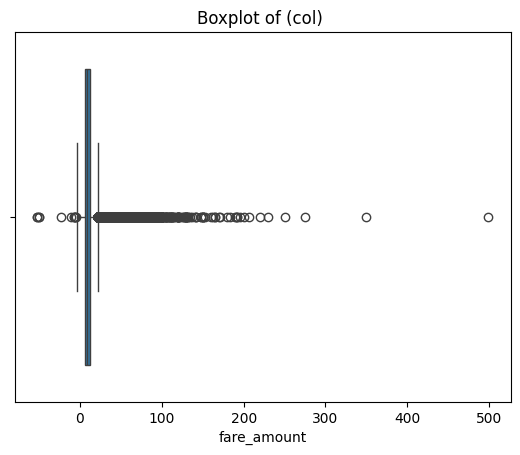

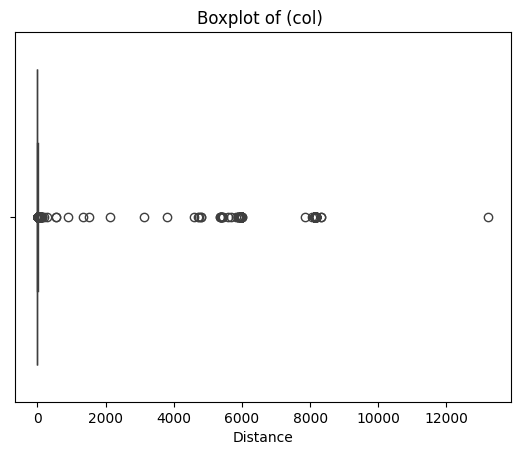

In [135]:
columns=["fare_amount", "Distance"]

for col in columns :
    #plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of (col) ")
    plt.show()

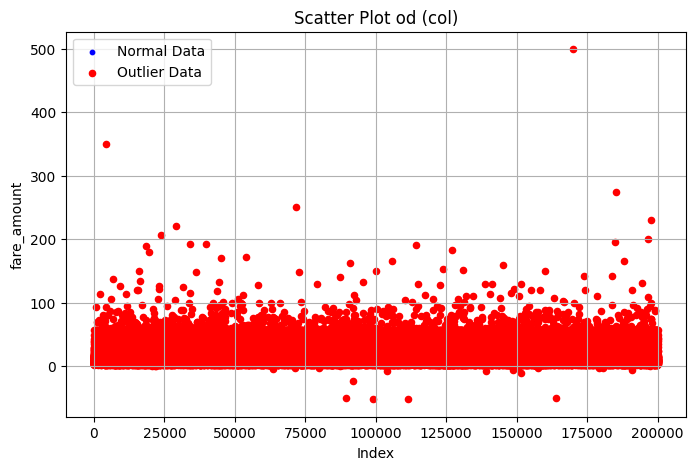

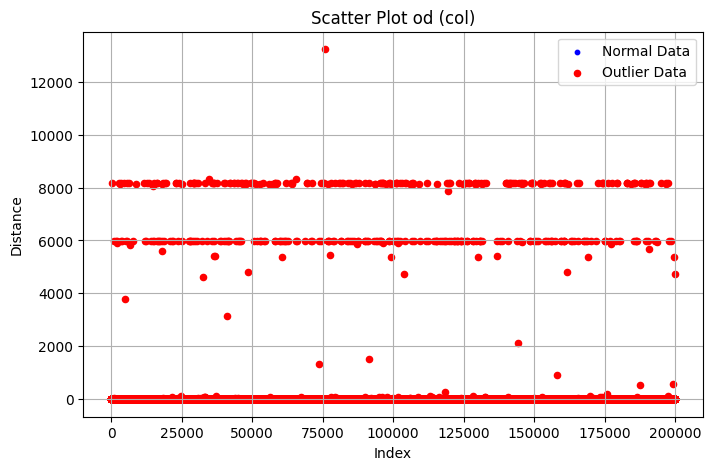

In [137]:
for col in columns:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    outliers = df[(df[col]<lower)|(df[col]>upper)]

    plt.figure(figsize=(8,5))

    plt.scatter(
        df.index,
        df[col],
        color="blue",
        s=10,
        label="Normal Data"
    )

    
    plt.scatter(
        df.index,
        df[col],
        color="red",
        s=20,
        label="Outlier Data"
    )

    plt.title(f"Scatter Plot od (col)")
    plt.xlabel("Index")
    plt.ylabel(col)
    plt.legend()
    plt.grid(True)
    plt.show()


In [139]:
columns = ["fare_amount" ,"Distance"]

for col in columns:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    df = df[(df[col]>=lower)&(df[col]<=upper)]

print("Dataset Shape",df.shape)

Dataset Shape (166842, 7)


In [142]:
x=df.drop("fare_amount",axis=1)

#Target (Dependent Variables)
y=df["fare_amount"]

print("freatures : ")
print(X.head())

print("\nTarget : ")
print(y.head())

freatures : 
   passenger_count  Year  Month  Day  Day_Type  Distance
0                1  2015      5    7         1  0.025494
1                1  2009      7   17         2  0.029661
3                3  2009      6   26         2  0.902166
5                1  2011      2   12         2  0.000000
7                1  2012     12   11         1  0.000000

Target : 
0    7.5
1    7.7
3    5.3
5    4.9
7    2.5
Name: fare_amount, dtype: float64


In [143]:
from sklearn.model_selection import train_test_split

x_train , x_test ,y_train ,y_test = train_test_split( x , y , test_size=0.20 , random_state=42 )
print("Training Data",x_train.shape)
print("Testing  Data",x_test.shape)


Training Data (133473, 6)
Testing  Data (33369, 6)


In [148]:
lr_model = LinearRegression()

lr_model.fit(x_train, y_train)

y_pred_lr = lr_model.predict(x_test)

print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


In [151]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)

lr_mse = mean_squared_error(y_test, y_pred_lr)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Results
-------------------------
MAE: 2.1961263243080227
MSE: 7.878735295123255
RMSE: 2.8069084942554245
R2 Score: 0.2737944408077668


In [152]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)

y_pred_rf = rf_model.predict(x_test)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [153]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_mse = mean_squared_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
---------------------
MAE: 2.181378234162335
MSE: 7.875232794409907
RMSE: 2.806284517722661
R2 Score: 0.2741172763129377


In [154]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],

    "MAE": [
        lr_mae,
        rf_mae
    ],

    "MSE": [
        lr_mse,
        rf_mse
    ],

    "RMSE": [
        lr_rmse,
        rf_rmse
    ],

    "R2 Score": [
        lr_r2,
        rf_r2
    ]
})

print(results)

                      Model       MAE       MSE      RMSE  R2 Score
0         Linear Regression  2.196126  7.878735  2.806908  0.273794
1  Random Forest Regression  2.181378  7.875233  2.806285  0.274117
